# Phase 7 — Explicabilité du modèle (SHAP)

**Objectif :** comprendre **pourquoi** le modèle juge un client à risque, au niveau global (quelles variables comptent) et individuel (pourquoi ce client-là). Un score sans explication n'aide pas le conseiller à choisir le bon levier de rétention.

**Plan**
1. Importance globale des variables, confrontée à l'EDA
2. Effet de chaque variable sur le risque
3. Explications individuelles
4. Limites de l'interprétation

**SHAP en deux phrases.** SHAP répartit la prédiction d'un client entre ses variables : chaque variable reçoit une **contribution** qui pousse le risque vers le haut ou vers le bas, par rapport à un client de référence. Les contributions **s'additionnent exactement** au score du modèle.

**Cas de la régression logistique.** SHAP y est **exact** (pas d'approximation) : contribution = coefficient × (valeur du client − valeur moyenne). Les contributions s'expriment en **log-odds** (logarithme de la cote `p / (1 − p)`), l'échelle sur laquelle le modèle est additif. Pour les lire : une contribution de **+0,7** multiplie la cote de départ par e^0,7 ≈ **2**.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.data import load_clean
from churn.eda import churn_rate_table
from churn.explain import ChurnExplainer, FEATURE_LABELS, VALUE_LABELS
from churn.features import split_data
from churn.models import load_model
from churn.viz import set_style, save_fig, fmt_pct, fmt_int, BLUE, ORANGE, AQUA, TEXT, TEXT_SECONDARY, GRID, SURFACE

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
dec = lambda v, d=2: f"{v:.{d}f}".replace(".", ",")
sigmoid = lambda z: 1 / (1 + np.exp(-z))

X_train, X_test, y_train, y_test = split_data(load_clean())
model, card = load_model("churn_model")
explainer = ChurnExplainer(model, background=X_train)   # référence : les clients d'entraînement
contrib_train = explainer.grouped_values(X_train)       # contributions par variable d'origine
print(f"{contrib_train.shape[1]} variables expliquées pour {fmt_int(len(contrib_train))} clients")
print(f"Valeur de base : {dec(explainer.base_value)} en log-odds, soit un risque de {fmt_pct(sigmoid(explainer.base_value))}")

17 variables expliquées pour 5 634 clients
Valeur de base : -1,59 en log-odds, soit un risque de 16,9 %


**À propos de la valeur de base.** C'est le score du client « moyen » (moyenne de chaque colonne), soit 16,9 % de risque, et non le taux de churn moyen (26,5 %). Les deux diffèrent parce que la moyenne est prise sur l'échelle des log-odds : la sigmoïde n'étant pas linéaire, le risque du client moyen n'est pas le risque moyen des clients. Ce n'est qu'un point de départ : seules les contributions, qui s'y ajoutent, portent l'explication.

## 1. Importance globale des variables

L'importance d'une variable = **contribution absolue moyenne** sur l'ensemble des clients : de combien, en moyenne, elle déplace le score d'un client.

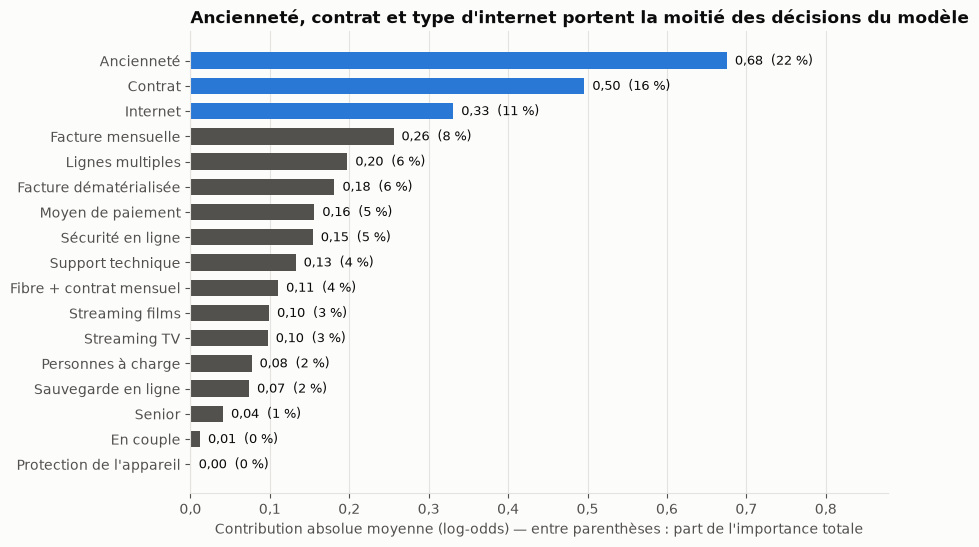

In [2]:
importance = contrib_train.abs().mean().sort_values()
labels = [FEATURE_LABELS[v] for v in importance.index]
share = importance / importance.sum()

fig, ax = plt.subplots(figsize=(9, 6))
colors = [BLUE if v in importance.index[-3:] else TEXT_SECONDARY for v in importance.index]
ax.barh(labels, importance, color=colors, height=0.65)
for i, (v, s) in enumerate(zip(importance, share)):
    ax.text(v + 0.01, i, f"{dec(v)}  ({fmt_pct(s, 0)})", va="center", fontsize=9, color=TEXT)
ax.set_xlim(0, importance.max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: dec(v, 1))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Contribution absolue moyenne (log-odds) — entre parenthèses : part de l'importance totale")
ax.set_title("Ancienneté, contrat et type d'internet portent la moitié des décisions du modèle")
save_fig(fig, "07_importance_globale.png")
plt.show()

**Lecture :**
- Le trio **ancienneté – contrat – type d'internet** concentre **près de la moitié** de l'importance totale. On retrouve les insights n° 1, 2 et 3 de l'EDA.
- **Le genre n'apparaît pas** : il a été retiré en Phase 4 (aucun lien avec le churn).
- « Protection de l'appareil » a une importance nulle : la régularisation Elastic Net a **mis son coefficient à zéro**, car l'information est déjà portée par les autres services.

### 1.1 Effet brut (EDA) contre effet propre (modèle)

L'EDA comparait des **taux bruts** : les clients en chèque électronique partent plus, mais ils ont aussi plus souvent un contrat mensuel et peu d'ancienneté. Le modèle, lui, mesure l'effet **propre** de chaque variable, **à autres variables fixées**.

On compare les deux sur la même échelle : le **rapport de cotes** (combien de fois la cote de départ est multipliée entre deux modalités). Pour le modèle, il vaut e^(écart de contribution).

In [3]:
pairs = [  # (variable, modalité à risque, modalité de référence, libellé)
    ("Contract", "Month-to-month", "Two year", "Contrat mensuel vs 2 ans"),
    ("InternetService", "Fiber optic", "DSL", "Fibre vs DSL"),
    ("PaymentMethod", "Electronic check", "Credit card (automatic)", "Chèque électronique vs carte auto."),
    ("OnlineSecurity", "No", "Yes", "Sans vs avec sécurité en ligne"),
    ("TechSupport", "No", "Yes", "Sans vs avec support technique"),
    ("PaperlessBilling", "Yes", "No", "Facture dématérialisée vs papier"),
    ("Dependents", "No", "Yes", "Sans vs avec personnes à charge"),
    ("SeniorCitizen", "Yes", "No", "Senior vs non senior"),
]
odds = lambda r: r / (1 - r)
train_df = X_train.assign(Churn=y_train)
internet_users = train_df["InternetService"] != "No"
rows = []
for var, risky, ref, label in pairs:
    # Services optionnels : comparaison parmi les clients ayant internet (sinon « Non » mélange deux populations)
    data = train_df[internet_users] if var in ("OnlineSecurity", "TechSupport") else train_df
    rates = churn_rate_table(data, var)["churn_rate"]
    rates.index = rates.index.astype(str)
    c = contrib_train[var].groupby(X_train[var].astype(str)).mean()
    rows.append({"comparaison": label,
                 "taux brut (risque)": rates[risky], "taux brut (référence)": rates[ref],
                 "rapport de cotes brut (EDA)": odds(rates[risky]) / odds(rates[ref]),
                 "rapport de cotes propre (modèle)": np.exp(c[risky] - c[ref])})
or_table = pd.DataFrame(rows).set_index("comparaison")
or_table["part de l'effet brut conservée"] = np.log(or_table["rapport de cotes propre (modèle)"]) / np.log(or_table["rapport de cotes brut (EDA)"])
or_table.style.format({"taux brut (risque)": "{:.1%}", "taux brut (référence)": "{:.1%}",
                       "rapport de cotes brut (EDA)": "×{:.1f}", "rapport de cotes propre (modèle)": "×{:.1f}",
                       "part de l'effet brut conservée": "{:.0%}"})

,taux brut (risque),taux brut (référence),rapport de cotes brut (EDA),rapport de cotes propre (modèle),part de l'effet brut conservée
comparaison,,,,,
Contrat mensuel vs 2 ans,42.7%,2.9%,×25.3,×3.9,42%
Fibre vs DSL,42.1%,18.7%,×3.2,×1.6,41%
Chèque électronique vs carte auto.,45.7%,14.9%,×4.8,×1.4,23%
Sans vs avec sécurité en ligne,41.9%,14.4%,×4.3,×1.5,26%
Sans vs avec support technique,41.8%,15.2%,×4.0,×1.4,23%
Facture dématérialisée vs papier,33.8%,16.0%,×2.7,×1.5,38%
Sans vs avec personnes à charge,31.4%,15.2%,×2.6,×1.2,20%
Senior vs non senior,41.1%,23.7%,×2.2,×1.2,19%


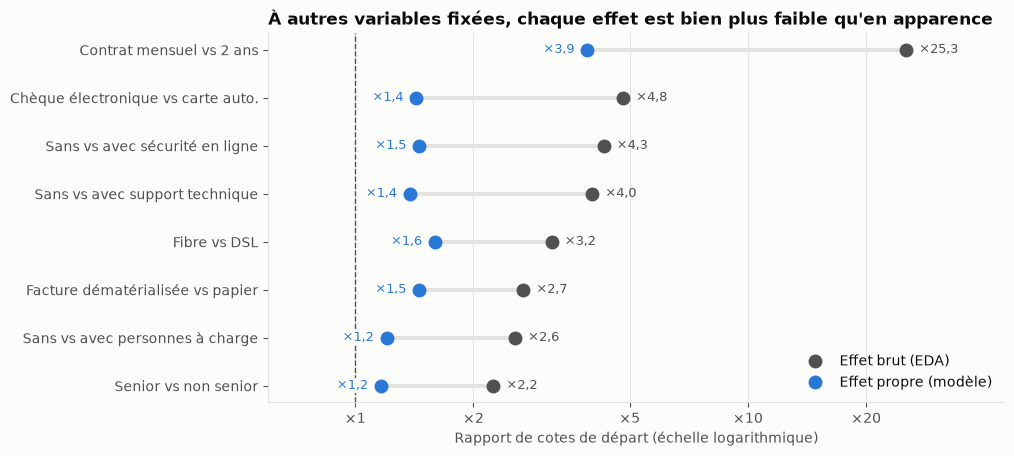

In [4]:
t = or_table.sort_values("rapport de cotes brut (EDA)")
fig, ax = plt.subplots(figsize=(9.5, 4.8))
for i, (name, row) in enumerate(t.iterrows()):
    raw, adj = row["rapport de cotes brut (EDA)"], row["rapport de cotes propre (modèle)"]
    ax.plot([adj, raw], [i, i], color=GRID, lw=3, zorder=1)
    ax.plot(raw, i, "o", markersize=9, color=TEXT_SECONDARY, zorder=2, label="Effet brut (EDA)" if i == 0 else None)
    ax.plot(adj, i, "o", markersize=9, color=BLUE, zorder=3, label="Effet propre (modèle)" if i == 0 else None)
    ax.text(raw * 1.08, i, f"×{dec(raw, 1)}", va="center", fontsize=9, color=TEXT_SECONDARY)
    ax.text(adj / 1.08, i, f"×{dec(adj, 1)}", va="center", ha="right", fontsize=9, color=BLUE, zorder=4,
            bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1))
ax.axvline(1, color=TEXT_SECONDARY, lw=1, ls="--")
ax.set_xscale("log")
ax.set_xlim(0.6, 45)
ax.set_xticks([1, 2, 5, 10, 20], ["×1", "×2", "×5", "×10", "×20"])
ax.minorticks_off()
ax.set_yticks(range(len(t)), t.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Rapport de cotes de départ (échelle logarithmique)")
ax.legend(loc="lower right")
ax.set_title("À autres variables fixées, chaque effet est bien plus faible qu'en apparence")
save_fig(fig, "07_effet_brut_vs_propre.png")
plt.show()

**Lecture :** pour chaque variable, l'effet propre (bleu) est **nettement plus faible** que l'effet brut (gris). Une grande partie de l'écart brut s'explique par d'**autres** variables qui voyagent ensemble : contrat mensuel, faible ancienneté, fibre, chèque électronique se cumulent chez les mêmes clients.

- **Contrat** : le rapport brut ×25 tombe à ×4 environ. Il reste un effet fort, mais une partie du « contrat mensuel » est en réalité de la **faible ancienneté**.
- **Senior** : l'effet brut (×2,2) **fond en grande partie** (×1,2 à autres variables fixées). Les seniors partent plus parce qu'ils ont plus souvent la fibre et un contrat mensuel, pas parce qu'ils sont seniors. **Cibler les seniors en tant que tels serait une erreur.**
- **Chèque électronique** : l'effet propre (×1,4) existe mais est modeste. Inciter au prélèvement automatique reste une piste, à valider par un test.
- **Fibre** : ×1,6 ne mesure que la variable « Internet ». La fibre agit aussi via la **facture** (plus élevée) et la feature **fibre + contrat mensuel** : son poids total est plus important. C'est une limite des comparaisons variable par variable quand les variables sont liées (voir section 4).

C'est un apport majeur du modèle par rapport à l'EDA : **démêler** des facteurs qui se cumulent.